<a href="https://www.kaggle.com/code/tarzon/telco-customer-churn-prediction?scriptVersionId=358228124" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Telco_Customer_Churn_Prediction

## Project Objective

The objective of this project is to identify the factors and behavioral patterns associated with customers who have churned, and use these patterns to identify existing customers who are at high risk of churning so that the company can take targeted retention actions.

This project follows an end-to-end machine learning workflow, covering data understanding, data quality assessment, data cleaning, exploratory data analysis, feature engineering, model development, evaluation, and business recommendations.

📖 This notebook has the code. The full walkthrough of the decisions, the overfitting lesson and the retention strategy is on Medium: [Customer Churn Prediction with Machine Learning: An End-to-End Telco Case Study]([https://medium.com/@parulrajput27/01c51ddaccfc?source=friends_link&sk=4085e3287c367a8d0da645f82560fa7b)

## Import Libraries

The following Python libraries are used for data manipulation, numerical analysis, visualization, and exploratory data analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Load Dataset

The dataset contains customer-level information related to demographics, services, contracts, billing, and churn status.

In [2]:
df=pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

## Data Understanding

The objective of this stage is to understand the structure, size, variables, data types, and general characteristics of the dataset before performing any cleaning or analysis.

In [3]:
### Preview the Dataset
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Dataset Shape
df.shape

(7043, 21)

The dataset contains 7,043 customer records and 21 variables.

## Column Names

The dataset contains demographic, service, contract, billing, and churn-related variables.

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

# Dataset Information

The `info()` method is used to examine the data types and non-null counts of all variables.

This step also helps identify potential data quality issues, such as numerical variables stored as text.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Observation

Most variables have appropriate data types. However, `TotalCharges` is stored as an `object` data type even though it represents a numerical monetary value.

This will be investigated during the **Data Quality Assessment and Data Cleaning** stages.

### Descriptive Statistics

Descriptive statistics are examined for numerical variables to understand their distributions and identify potential range or validity issues.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


###  Initial Data Understanding

- The dataset contains **7,043 customer records** and **21 columns**.
- Each row represents an individual customer.
- The dataset contains demographic information, service details, account information, billing information, and customer churn status.
- The target variable is `Churn`, which indicates whether a customer has left the company.
- `customerID` is a unique identifier and will not be used as a predictive feature.
- The dataset contains both numerical and categorical variables.
- `TotalCharges` is stored as an object data type even though it represents a numerical monetary value. This requires further investigation during data quality assessment.

### Explore Categorical Variables

The unique values of categorical variables are examined to identify the possible categories present in the dataset and detect any unexpected or inconsistent values.

In [8]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(df[col].unique())


customerID:
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']

gender:
['Female' 'Male']

Partner:
['Yes' 'No']

Dependents:
['No' 'Yes']

PhoneService:
['No' 'Yes']

MultipleLines:
['No phone service' 'No' 'Yes']

InternetService:
['DSL' 'Fiber optic' 'No']

OnlineSecurity:
['No' 'Yes' 'No internet service']

OnlineBackup:
['Yes' 'No' 'No internet service']

DeviceProtection:
['No' 'Yes' 'No internet service']

TechSupport:
['No' 'Yes' 'No internet service']

StreamingTV:
['No' 'Yes' 'No internet service']

StreamingMovies:
['No' 'Yes' 'No internet service']

Contract:
['Month-to-month' 'One year' 'Two year']

PaperlessBilling:
['Yes' 'No']

PaymentMethod:
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']

TotalCharges:
['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']

Churn:
['No' 'Yes']


### Target Variable Analysis

`Churn` is the target variable for this project.

It indicates whether a customer has left the company:

- `Yes` → Customer churned
- `No` → Customer remained with the company

Understanding the target distribution is important because class imbalance can affect machine learning model evaluation.

In [9]:
df['Churn'].value_counts(normalize=True) * 100

No     73.463013
Yes    26.536987
Name: Churn, dtype: float64

## Data Quality Assessment

The purpose of this stage is to identify potential data quality problems before modifying the dataset.

The following areas are assessed:

- Missing values
- Duplicate records
- Duplicate customer IDs
- Incorrect data types
- Blank or invalid values
- Numerical range validity
- Categorical consistency

### Missing Values

First, we check for missing values represented as `NaN` or `None`.

In [10]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Observation

No explicit missing values are reported by `isnull()`.

However, `TotalCharges` is stored as an object, so blank strings may not be recognized as missing values. Therefore, this column requires additional investigation.

### Duplicate Records

Duplicate rows are checked to determine whether the dataset contains repeated customer records.

In [11]:
df.duplicated().sum()

0

### Observation

No duplicate records were identified.

### Duplicate Customer IDs

Since `customerID` is expected to uniquely identify each customer, duplicate customer IDs are checked separately.

In [12]:
df['customerID'].duplicated().sum()

0

### Observation

No duplicate customer IDs were identified. Each customer record has a unique identifier.

In [13]:
df['TotalCharges'].value_counts().head(10)

         11
20.2     11
19.75     9
20.05     8
19.9      8
19.65     8
45.3      7
19.55     7
20.15     6
20.25     6
Name: TotalCharges, dtype: int64

### Observation

There are **11 blank values** in `TotalCharges`.

These values are not detected by `isnull()` because they are stored as blank strings rather than actual missing values.

In [14]:
## Invalid Numeric Values
pd.to_numeric(df['TotalCharges'], errors='coerce').isna().sum()

11

In [15]:
df[df['TotalCharges'].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


### Observation

The affected customers have `tenure = 0`.

Since `TotalCharges` represents the total amount charged over the customer's tenure, a tenure of zero indicates that these customers have not accumulated any charges.

Therefore, replacing these blank values with `0` is logically appropriate for this dataset.

# Data Cleaning

Based on the Data Quality Assessment, the main data quality issue identified is the presence of 11 blank values in `TotalCharges`.

The cleaning process will:

1. Convert blank strings to zero where logically appropriate.
2. Convert `TotalCharges` from object to numeric.
3. Verify that no missing values remain.
4. Validate numerical ranges.
5. Keep `customerID` in the cleaned dataset because it may be useful for identifying individual customers later, although it will not be used as a model feature.

In [16]:
# Clean TotalCharges
df['TotalCharges'] = df['TotalCharges'].str.strip().replace('', '0')

In [17]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

In [18]:
#Verify Data Type
df['TotalCharges'].dtype

dtype('float64')

In [19]:
#Verify Missing Values
df['TotalCharges'].isnull().sum()

0

### Observation

`TotalCharges` has been successfully converted from `object` to `float64`, and no missing values remain in the column.

In [20]:
# Verify Cleaned Values
df[['tenure', 'MonthlyCharges', 'TotalCharges']].head(10)

,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65
5,8,99.65,820.50
6,22,89.10,1949.40
7,10,29.75,301.90
8,28,104.80,3046.05
9,62,56.15,3487.95


### Numerical Variable Validation

The numerical variables are examined to verify that their values fall within reasonable ranges.

In [21]:
df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [22]:
print(
    "Invalid SeniorCitizen values:",
    (~df['SeniorCitizen'].isin([0, 1])).sum()
)

print(
    "Invalid tenure values:",
    ((df['tenure'] < 0) | (df['tenure'] > 72)).sum()
)

print(
    "Invalid MonthlyCharges values:",
    (df['MonthlyCharges'] < 0).sum()
)

print(
    "Invalid TotalCharges values:",
    (df['TotalCharges'] < 0).sum()
)

Invalid SeniorCitizen values: 0
Invalid tenure values: 0
Invalid MonthlyCharges values: 0
Invalid TotalCharges values: 0


### Observation

The numerical variables fall within their expected logical ranges:

- `SeniorCitizen` contains only 0 and 1.
- `tenure` ranges from 0 to 72 months.
- `MonthlyCharges` contains no negative values.
- `TotalCharges` contains no negative values.

No additional numerical cleaning is required at this stage.

In [23]:
#Check Unique Numerical Values
df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].nunique()

SeniorCitizen        2
tenure              73
MonthlyCharges    1585
TotalCharges      6531
dtype: int64

# Data Cleaning Summary

The Data Quality Assessment identified one primary data quality issue: blank values in `TotalCharges`.

### Actions Taken

- No duplicate records were found.
- No duplicate customer IDs were found.
- No explicit missing values were found through `isnull()`.
- 11 blank strings were identified in `TotalCharges`.
- The affected customers had `tenure = 0`, making `TotalCharges = 0` logically appropriate.
- `TotalCharges` was converted from `object` to `float64`.
- Numerical variables were validated for logical ranges.
- `customerID` was retained for customer identification but will be excluded from machine learning features.

The dataset is now ready for exploratory data analysis.

# Data Dictionary

The Data Dictionary provides a structured description of each variable, including its data type, number of non-null observations, number of unique values, business meaning, and role in the machine learning project.

In [24]:
data_dictionary = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.astype(str).values,
    'Non-Null Count': df.notnull().sum().values,
    'Unique Values': df.nunique().values
})

In [25]:
data_dictionary['Description'] = [
    'Unique identifier assigned to each customer',
    'Customer gender',
    'Whether the customer is a senior citizen',
    'Whether the customer has a partner',
    'Whether the customer has dependents',
    'Number of months the customer has been with the company',
    'Whether the customer has phone service',
    'Whether the customer has multiple phone lines',
    'Type of internet service',
    'Whether the customer subscribes to online security',
    'Whether the customer subscribes to online backup',
    'Whether the customer subscribes to device protection',
    'Whether the customer subscribes to technical support',
    'Whether the customer subscribes to streaming TV',
    'Whether the customer subscribes to streaming movies',
    'Customer contract type',
    'Whether the customer uses paperless billing',
    'Customer payment method',
    'Monthly amount charged to the customer',
    'Total amount charged to the customer during their tenure',
    'Whether the customer left the company'
]

In [26]:
data_dictionary['Role'] = [
    'Identifier',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Feature',
    'Target'
]
data_dictionary

,Column,Data Type,Non-Null Count,Unique Values,Description,Role
0,customerID,object,7043,7043,Unique identifier assigned to each customer,Identifier
1,gender,object,7043,2,Customer gender,Feature
2,SeniorCitizen,int64,7043,2,Whether the customer is a senior citizen,Feature
3,Partner,object,7043,2,Whether the customer has a partner,Feature
4,Dependents,object,7043,2,Whether the customer has dependents,Feature
5,tenure,int64,7043,73,Number of months the customer has been with th...,Feature
6,PhoneService,object,7043,2,Whether the customer has phone service,Feature
7,MultipleLines,object,7043,3,Whether the customer has multiple phone lines,Feature
8,InternetService,object,7043,3,Type of internet service,Feature
9,OnlineSecurity,object,7043,3,Whether the customer subscribes to online secu...,Feature


### Final Dataset Check

Before moving to Exploratory Data Analysis, we perform a final check to confirm that the dataset is structurally and qualitatively ready for analysis.

In [27]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (7043, 21)

Missing Values:
0

Duplicate Rows:
0

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


## Exploratory Data Analysis (EDA)

Our EDA will have 5 sections:

1. Overall Churn Analysis
2. Customer Demographics vs Churn
3. Customer Account & Tenure vs Churn
4. Services & Contract vs Churn
5. Billing & Payment Behavior vs Churn

Then we'll finish with a Churn Pattern Summary.

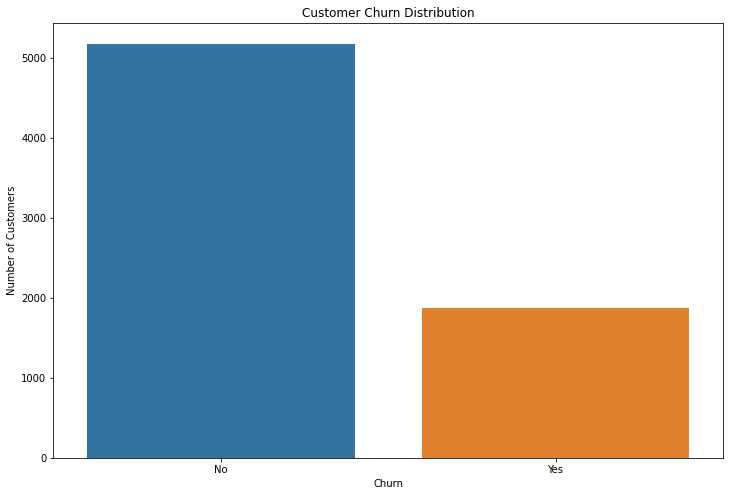

In [28]:
churn_counts = df['Churn'].value_counts()

plt.figure(figsize=(12,8))
sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

In [29]:
churn_pct = (
    df['Churn']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_pct

No     73.46
Yes    26.54
Name: Churn, dtype: float64

### Insight

The dataset contains a larger proportion of customers who did not churn, with 73.46% retained customers and 26.54% churned customers.
This indicates that the dataset has a moderate class imbalance. Therefore, model evaluation should consider metrics such as Precision, Recall, F1-score and ROC-AUC rather than relying only on accuracy.

## Customer Demographics and Churn

### Gender and Churn

We examine whether churn rates differ between male and female customers.

In [30]:
gender_churn = pd.crosstab(
    df['gender'],
    df['Churn'],
    normalize='index'
).mul(100)

gender_churn

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


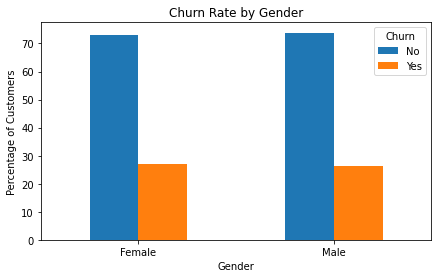

In [31]:
gender_churn.plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

### Observation

Churn rates are very similar for male and female customers.

Female customers have a churn rate of 26.92%, compared with 26.16% for male customers, a difference of less than 1 percentage point.

This suggests that gender has a relatively weak association with churn compared with other customer characteristics examined in the analysis.

### Senior Citizen vs Churn

In [32]:
senior_churn = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
).mul(100)

senior_churn

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


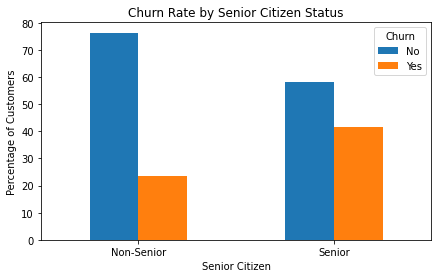

In [33]:
senior_churn.plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Churn Rate by Senior Citizen Status')
plt.xlabel('Senior Citizen')
plt.ylabel('Percentage of Customers')
plt.xticks(
    ticks=[0, 1],
    labels=['Non-Senior', 'Senior'],
    rotation=0
)
plt.legend(title='Churn')
plt.show()

### Observation

Senior citizens show a substantially higher churn rate than non-senior customers.

The churn rate among senior citizens is 41.68%, compared with 23.61% among non-senior customers.

This represents a difference of approximately 18 percentage points, indicating that senior citizen status is strongly associated with churn in this dataset.

Senior customers may therefore represent an important segment for targeted retention analysis.

### Partner vs Churn

In [34]:
partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
).mul(100)

partner_churn

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


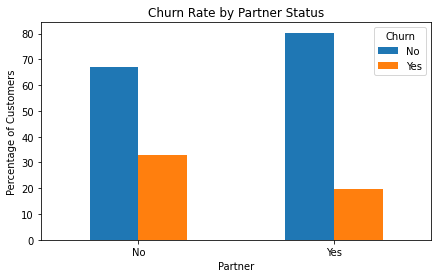

In [35]:
partner_churn.plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Churn Rate by Partner Status')
plt.xlabel('Partner')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

### Observation

Customers without a partner have a considerably higher churn rate than customers with a partner.

The churn rate is 32.96% among customers without a partner, compared with 19.66% among customers with a partner.

This difference of approximately 13 percentage points suggests that partner status is associated with customer retention.

However, this relationship may also reflect other factors such as tenure, contract type, or customer demographics, so it should not be interpreted as a causal relationship.

### Dependents vs Churn

In [36]:
dependents_churn = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
).mul(100)

dependents_churn

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


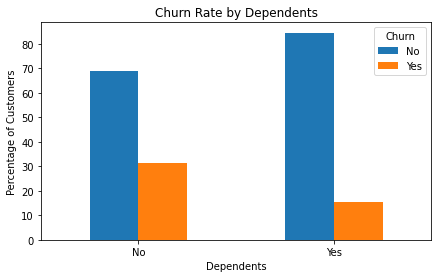

In [37]:
dependents_churn.plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Churn Rate by Dependents')
plt.xlabel('Dependents')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

### Observation

Customers without dependents have approximately twice the churn rate of customers with dependents.

The churn rate is 31.28% for customers without dependents, compared with 15.45% for customers with dependents.

This indicates a strong association between dependent status and customer retention.

Customers without dependents may therefore represent a higher-risk segment, although the relationship may be influenced by other customer characteristics.

##  Customer Account Characteristics and Churn

Customer account characteristics can provide insight into customer loyalty and retention.

We will examine tenure, contract type, paperless billing, and payment method.

### Tenure and Churn

Tenure represents the number of months a customer has remained with the company.

We examine whether customers with shorter or longer relationships with the company have different churn behavior.

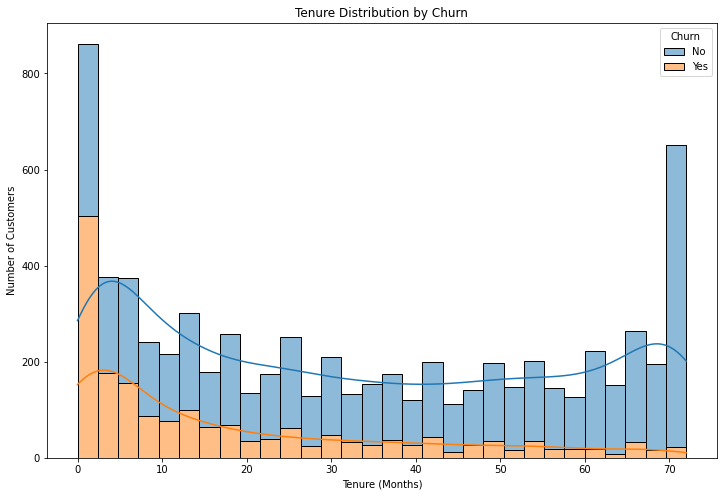

In [38]:
plt.figure(figsize=(12, 8))

sns.histplot(
    data=df,
    x='tenure',
    hue='Churn',
    bins=30,
    kde=True,
    multiple='stack'
)

plt.title('Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()

In [39]:
tenure_churn = (
    df.groupby('Churn')['tenure']
    .agg(['mean', 'median'])
    .round(2)
)

tenure_churn

,mean,median
Churn,,
No,37.57,38.0
Yes,17.98,10.0


### Observation

Churned customers have substantially shorter tenure than customers who remain with the company.

The average tenure of churned customers is 17.98 months, compared with 37.57 months for retained customers.

The difference is even more pronounced in the median: churned customers have a median tenure of only 10 months, compared with 38 months for retained customers.

The distribution therefore suggests that customers in the early stages of their relationship with the company are at considerably higher risk of churn.

### Business Implication

The early customer lifecycle appears to be a critical retention period.

The company could consider stronger onboarding, early engagement, and proactive support during the first several months of a customer's relationship.

### Contract vs Churn

In [40]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
).mul(100)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


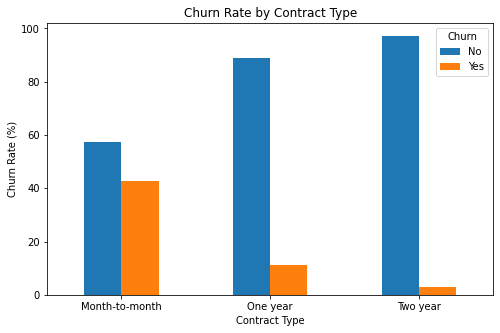

In [41]:
contract_churn.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

### Observation

Contract type shows one of the strongest associations with churn in the dataset.

Customers on month-to-month contracts have a churn rate of 42.71%, compared with 11.27% for one-year contracts and only 2.83% for two-year contracts.

The churn rate therefore decreases substantially as the contract commitment increases.

Month-to-month customers represent a particularly high-risk segment and should receive greater attention in retention strategies.

### Paperless Billing vs Churn

In [42]:
paperless_churn = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
).mul(100)

paperless_churn

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


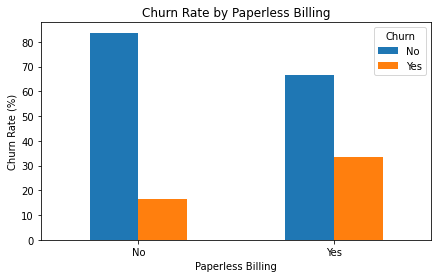

In [43]:
paperless_churn.plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Churn Rate by Paperless Billing')
plt.xlabel('Paperless Billing')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

### Observation

Customers using paperless billing have a substantially higher churn rate than customers who do not use paperless billing.

The churn rate is 33.57% among paperless billing customers, compared with 16.33% among customers who do not use paperless billing.

This represents a difference of approximately 17 percentage points.

Paperless billing is therefore associated with higher churn in this dataset. However, this relationship may be influenced by other factors such as payment method, contract type, or customer profile.

### Payment Method vs Churn

In [44]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
).mul(100)

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


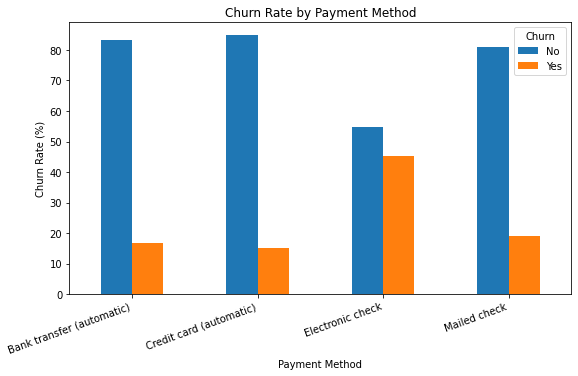

In [45]:
payment_churn.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=20, ha='right')
plt.legend(title='Churn')
plt.show()

### Observation

Payment method shows a substantial difference in churn rates.

Customers using electronic checks have the highest churn rate at 45.29%.

In comparison, churn rates are considerably lower for bank transfer (16.71%), mailed check (19.11%), and credit card (15.24%).

The electronic check segment therefore represents a particularly high-risk customer group and warrants further investigation.

### Services and Churn

Customers may have different levels of service adoption.

We examine whether the type of internet service and additional services are associated with different churn rates.

In [46]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
).mul(100)

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


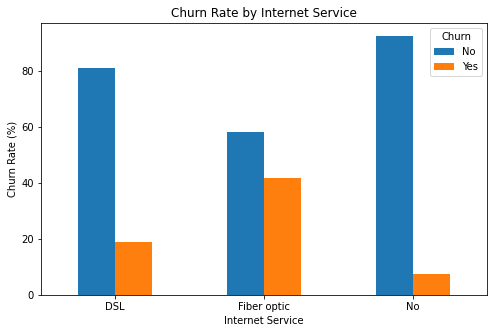

In [47]:
internet_churn.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.show()

### Observation

Internet service type is strongly associated with churn.

Customers using fiber optic internet have a churn rate of 41.89%, compared with 18.96% for DSL customers.

Customers without internet service have the lowest churn rate at 7.40%.

The high churn rate among fiber optic customers is particularly notable and should be investigated further, as it may be related to pricing, service experience, contract type, or other customer characteristics.

In [48]:
service_columns = [
    'PhoneService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

In [49]:
def churn_rate_by_category(data, column):
    result = pd.crosstab(
        data[column],
        data['Churn'],
        normalize='index'
    ).mul(100)

    return result

In [50]:
for col in service_columns:
    print(f"\n--- {col} ---")
    display(churn_rate_by_category(df, col))


--- PhoneService ---


Churn,No,Yes
PhoneService,,
No,75.073314,24.926686
Yes,73.290363,26.709637



--- MultipleLines ---


Churn,No,Yes
MultipleLines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896



--- OnlineSecurity ---


...

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341



--- StreamingTV ---


Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188



--- StreamingMovies ---


Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


### Biling Characteristics and Churn

Billing behavior can provide important signals about customer churn.

We examine whether churned customers differ in monthly charges and total charges compared with customers who remain.

### Monthly Charges vs Chrun

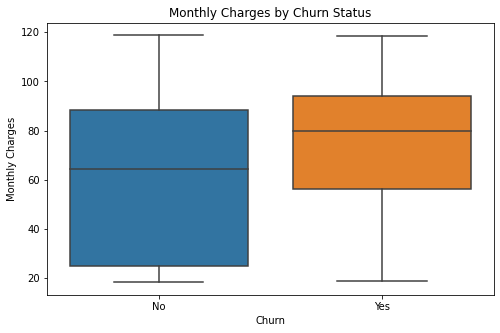

In [51]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()

In [52]:
df.groupby('Churn')['MonthlyCharges'].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

,mean,median,min,max
Churn,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


### Observation

Churned customers tend to have higher monthly charges than customers who remain with the company.

The average monthly charge among churned customers is 74.44, compared with 61.27 among retained customers.

The median monthly charge is also higher for churned customers, at 79.65 compared with 64.43.

This suggests that higher monthly charges are associated with increased churn risk in this dataset.

### Total Charges vs Chrun

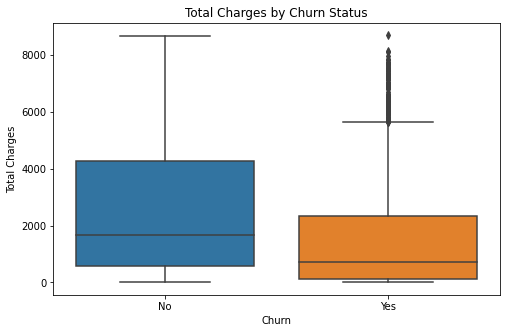

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='TotalCharges'
)

plt.title('Total Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Total Charges')
plt.show()

### Observation

The distribution of TotalCharges differs between churned and retained customers.

However, TotalCharges is strongly related to customer tenure because it represents the accumulated amount charged over the customer's relationship with the company.

Therefore, differences in TotalCharges should be interpreted alongside tenure rather than treated as an independent churn factor.

### Numerical Feature Relationships

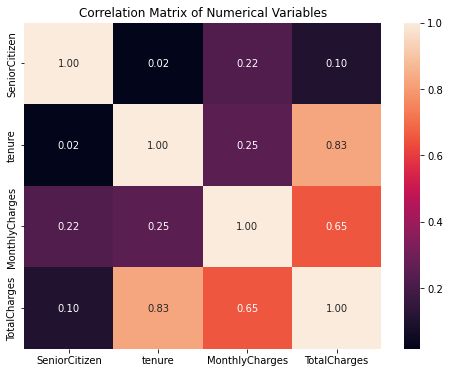

In [54]:
numeric_columns = [
    'SeniorCitizen',
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    df[numeric_columns].corr(),
    annot=True,
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Variables')
plt.show()

### Observation

The correlation matrix shows the relationships among the numerical variables.

A strong positive relationship is expected between `tenure` and `TotalCharges`, because customers who remain with the company for longer periods generally accumulate higher total charges.

`MonthlyCharges` also contributes to `TotalCharges`, although the relationship is influenced by the customer's tenure and service configuration.

Correlation measures linear association and does not establish causation. It also does not capture relationships involving categorical variables such as contract type or payment method.


##  Combined Churn Risk Patterns

The previous analysis examined individual factors associated with customer churn.

However, customer churn is likely influenced by multiple characteristics simultaneously.

In this section, we examine combinations of customer attributes to identify whether certain customer profiles have substantially higher churn rates.

The analysis will focus on:

- Contract type and tenure
- Contract type and payment method
- Contract type and internet service
- Tenure and monthly charges
- Internet service and additional support services

The purpose is to identify high-risk customer segments that may be useful for targeted retention strategies.

### Contract Type × Payment Method

In [55]:
contract_payment_churn = pd.crosstab(
    [df['Contract'], df['PaymentMethod']],
    df['Churn'],
    normalize='index'
).mul(100).round(2)

contract_payment_churn

Churn                                        No    Yes
Contract       PaymentMethod                          
Month-to-month Bank transfer (automatic)  65.87  34.13
               Credit card (automatic)    67.22  32.78
               Electronic check           46.27  53.73
               Mailed check               68.42  31.58
One year       Bank transfer (automatic)  90.28   9.72
               Credit card (automatic)    89.70  10.30
               Electronic check           81.56  18.44
               Mailed check               93.18   6.82
Two year       Bank transfer (automatic)  96.63   3.37
               Credit card (automatic)    97.76   2.24
               Electronic check           92.26   7.74
               Mailed check               99.21   0.79

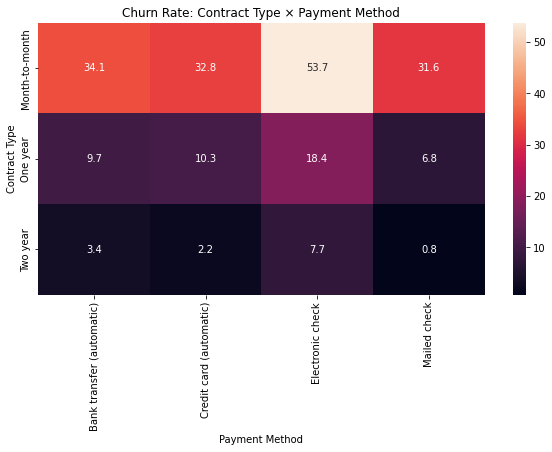

In [56]:
contract_payment_matrix = pd.crosstab(
    df['Contract'],
    df['PaymentMethod'],
    values=df['Churn'].map({'No': 0, 'Yes': 1}),
    aggfunc='mean'
).mul(100)

plt.figure(figsize=(10, 5))

sns.heatmap(
    contract_payment_matrix,
    annot=True,
    fmt='.1f'
)

plt.title('Churn Rate: Contract Type × Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Contract Type')
plt.show()

Month-to-month customers using electronic checks have the highest churn rate at 53.73%.

### Contract Type × Internet Service

We examine whether churn patterns across contract types differ depending on the customer's internet service.

In [57]:
contract_internet_matrix = pd.crosstab(
    df['Contract'],
    df['InternetService'],
    values=df['Churn'].map({'No': 0, 'Yes': 1}),
    aggfunc='mean'
).mul(100)

contract_internet_matrix.round(2)

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78


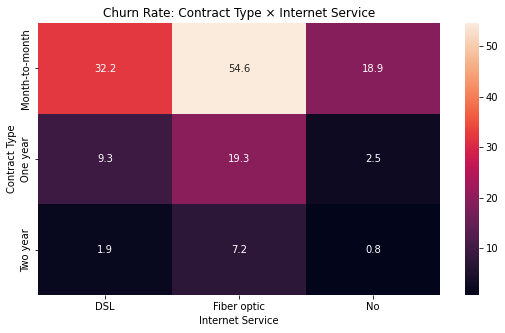

In [58]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    contract_internet_matrix,
    annot=True,
    fmt='.1f'
)

plt.title('Churn Rate: Contract Type × Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Contract Type')
plt.show()

Month-to-month customers with fiber optic service have the highest churn rate at 54.61%.

📖 This notebook has the code. The full walkthrough of the decisions, the overfitting lesson and the retention strategy is on Medium: [Customer Churn Prediction with Machine Learning: An End-to-End Telco Case Study]([https://medium.com/@parulrajput27/01c51ddaccfc?source=friends_link&sk=4085e3287c367a8d0da645f82560fa7b)

### Tenure Group × Contract Type

Since tenure is a continuous variable, we group customers into meaningful tenure bands to examine how churn changes across different stages of the customer lifecycle.### Tenure Group × Contract Type

Since tenure is a continuous variable, we group customers into meaningful tenure bands to examine how churn changes across different stages of the customer lifecycle.

In [59]:
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=[
        '0-6 months',
        '7-12 months',
        '13-24 months',
        '25-48 months',
        '49-72 months'
    ]
)

In [60]:
tenure_contract_matrix = pd.crosstab(
    df['TenureGroup'],
    df['Contract'],
    values=df['Churn'].map({'No': 0, 'Yes': 1}),
    aggfunc='mean'
).mul(100)

tenure_contract_matrix.round(2)

Contract,Month-to-month,One year,Two year
TenureGroup,,,
0-6 months,55.20,10.26,0.00
7-12 months,42.00,10.59,0.00
13-24 months,37.72,8.12,0.00
25-48 months,32.92,10.62,2.19
49-72 months,26.02,12.93,3.33


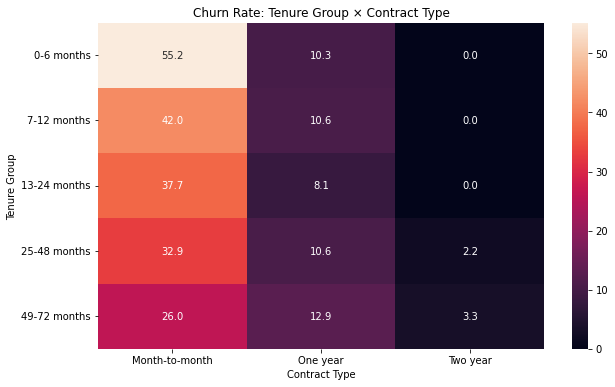

In [61]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    tenure_contract_matrix,
    annot=True,
    fmt='.1f'
)

plt.title('Churn Rate: Tenure Group × Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Tenure Group')
plt.show()

Customers with 0–6 months tenure on month-to-month contracts have a high churn rate of 55.20%.

### Tenure × Monthly Charges

We examine whether customers with shorter tenure and higher monthly charges show elevated churn rates.

In [62]:
df['MonthlyChargeGroup'] = pd.qcut(
    df['MonthlyCharges'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

In [63]:
tenure_charge_matrix = pd.crosstab(
    df['TenureGroup'],
    df['MonthlyChargeGroup'],
    values=df['Churn'].map({'No': 0, 'Yes': 1}),
    aggfunc='mean'
).mul(100)

tenure_charge_matrix.round(2)

MonthlyChargeGroup,Low,Medium,High
TenureGroup,,,
0-6 months,36.69,62.71,77.21
7-12 months,16.85,35.19,69.14
13-24 months,10.53,28.46,51.36
25-48 months,5.49,17.85,35.28
49-72 months,2.55,5.55,15.16


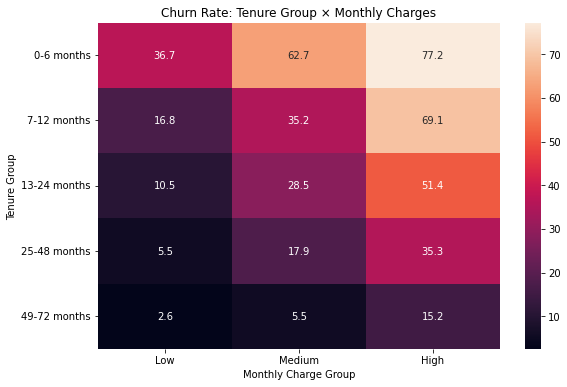

In [64]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    tenure_charge_matrix,
    annot=True,
    fmt='.1f'
)

plt.title('Churn Rate: Tenure Group × Monthly Charges')
plt.xlabel('Monthly Charge Group')
plt.ylabel('Tenure Group')
plt.show()

Customers with 0–6 months tenure and high monthly charges have the highest churn rate at 77.21%.

### Internet Service × Tech Support

The earlier analysis showed high churn among fiber optic customers and customers without technical support.

We examine whether these factors combine to identify an even higher-risk segment.

In [65]:
internet_support_matrix = pd.crosstab(
    df['InternetService'],
    df['TechSupport'],
    values=df['Churn'].map({'No': 0, 'Yes': 1}),
    aggfunc='mean'
).mul(100)

internet_support_matrix.round(2)

TechSupport,No,No internet service,Yes
InternetService,,,
DSL,27.76,NaN,9.68
Fiber optic,49.37,NaN,22.63
No,NaN,7.4,NaN


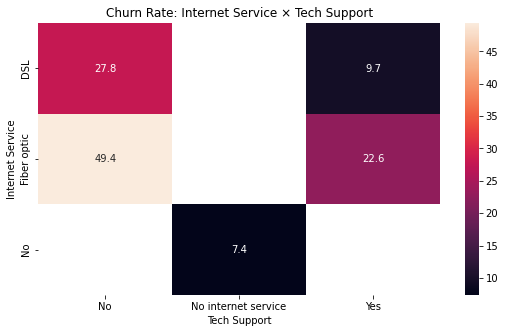

In [66]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    internet_support_matrix,
    annot=True,
    fmt='.1f'
)

plt.title('Churn Rate: Internet Service × Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Internet Service')
plt.show()

Fiber optic customers without tech support have a churn rate of 49.37%, compared with 22.63% for those with support.

### Internet Service × Online Security

In [67]:
internet_security_matrix = pd.crosstab(
    df['InternetService'],
    df['OnlineSecurity'],
    values=df['Churn'].map({'No': 0, 'Yes': 1}),
    aggfunc='mean'
).mul(100)

internet_security_matrix.round(2)

OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,27.96,NaN,9.49
Fiber optic,49.36,NaN,21.81
No,NaN,7.4,NaN


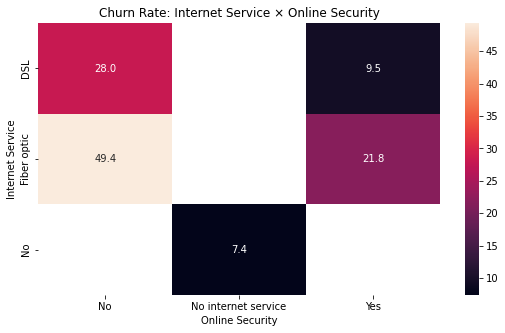

In [68]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    internet_security_matrix,
    annot=True,
    fmt='.1f'
)

plt.title('Churn Rate: Internet Service × Online Security')
plt.xlabel('Online Security')
plt.ylabel('Internet Service')
plt.show()

Fiber optic customers without online security have a churn rate of 49.36%, compared with 21.81% for those with security.

### Tenure × Contract × Monthly Charges.

In [69]:
three_way_1 = pd.crosstab(
    [df['TenureGroup'], df['Contract']],
    df['MonthlyChargeGroup'],
    values=df['Churn'].map({'No': 0, 'Yes': 1}),
    aggfunc='mean'
).mul(100).round(2)

three_way_1

MonthlyChargeGroup             Low  Medium    High
TenureGroup  Contract                             
0-6 months   Month-to-month  39.61   63.84   77.10
             One year         5.71   33.33  100.00
             Two year         0.00    0.00     NaN
7-12 months  Month-to-month  22.91   37.40   71.15
             One year         8.62   14.29   16.67
             Two year         0.00    0.00     NaN
13-24 months Month-to-month  18.99   34.04   53.85
             One year         3.67   11.43   22.22
             Two year         0.00    0.00    0.00
25-48 months Month-to-month  13.89   27.38   43.54
             One year         2.89    9.50   21.38
             Two year         1.14    3.45    4.88
49-72 months Month-to-month  17.65   15.85   30.97
             One year         2.83    6.70   19.20
             Two year         1.22    2.40    5.58

In [70]:
plot_data = three_way_1.reset_index().melt(
    id_vars=['TenureGroup', 'Contract'],
    var_name='MonthlyChargeGroup',
    value_name='ChurnRate'
)

plot_data.head()

,TenureGroup,Contract,MonthlyChargeGroup,ChurnRate
0,0-6 months,Month-to-month,Low,39.61
1,0-6 months,One year,Low,5.71
2,0-6 months,Two year,Low,0.00
3,7-12 months,Month-to-month,Low,22.91
4,7-12 months,One year,Low,8.62


In [71]:
import plotly.express as px

fig = px.bar(
    plot_data,
    x='TenureGroup',
    y='ChurnRate',
    color='MonthlyChargeGroup',
    facet_col='Contract',
    barmode='group',
    text='ChurnRate',
    title='Churn Rate by Tenure, Monthly Charges and Contract Type'
)

fig.update_traces(
    texttemplate='%{text:.1f}%',
    textposition='outside'
)

fig.update_layout(
    height=600,
    width=1200
)

fig.update_yaxes(title='Churn Rate (%)')
fig.update_xaxes(title='Tenure Group')

fig.show()

In [72]:
plot_data = (
    three_way_1
    .reset_index()
    .melt(
        id_vars=['TenureGroup', 'Contract'],
        var_name='MonthlyChargeGroup',
        value_name='ChurnRate'
    )
)

plot_data.head()

,TenureGroup,Contract,MonthlyChargeGroup,ChurnRate
0,0-6 months,Month-to-month,Low,39.61
1,0-6 months,One year,Low,5.71
2,0-6 months,Two year,Low,0.00
3,7-12 months,Month-to-month,Low,22.91
4,7-12 months,One year,Low,8.62


In [73]:
import plotly.express as px

fig = px.bar(
    plot_data,
    x='TenureGroup',
    y='ChurnRate',
    color='MonthlyChargeGroup',
    facet_col='Contract',
    barmode='group',
    text='ChurnRate',
    title='Churn Rate by Tenure, Monthly Charges and Contract Type',
    labels={
        'TenureGroup': 'Tenure Group',
        'ChurnRate': 'Churn Rate (%)',
        'MonthlyChargeGroup': 'Monthly Charges'
    }
)

fig.update_traces(
    texttemplate='%{text:.1f}%',
    textposition='outside'
)

fig.update_layout(
    height=600,
    width=1200,
    legend_title='Monthly Charges',
    title_x=0.5
)

fig.update_yaxes(range=[0, 85])

fig.show()

### Observation

Churn is highest among short-tenure customers with higher monthly charges,
particularly those on month-to-month contracts. The churn rate generally
declines as tenure increases, indicating that newer customers represent a
higher-risk segment.

The highest observed churn is 77.1% among customers with 0–6 months of tenure,
month-to-month contracts, and high monthly charges.

# Feature Engineering

In [74]:
X = df.drop(
    columns=['customerID', 'Churn', 'TenureGroup', 'MonthlyChargeGroup']
)

y = df['Churn']

In [75]:
X.shape

(7043, 19)

In [76]:
y.shape

(7043,)

In [77]:
numerical_features = [
    'SeniorCitizen',
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

In [78]:
categorical_features = [
    'gender',
    'Partner',
    'Dependents',
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaperlessBilling',
    'PaymentMethod'
]

In [79]:
print("Numerical:", len(numerical_features))
print("Categorical:", len(categorical_features))
print("Total:", len(numerical_features) + len(categorical_features))

Numerical: 4
Categorical: 15
Total: 19


In [80]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [81]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4930, 19)
X_test: (2113, 19)
y_train: (4930,)
y_test: (2113,)


### Preprocessing

In [82]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

In [83]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

In [84]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [85]:
X_train_processed.shape

(4930, 45)

In [86]:

X_test_processed.shape

(2113, 45)

In [87]:
print(y_train.value_counts())
print(y_test.value_counts())

No     3622
Yes    1308
Name: Churn, dtype: int64
No     1552
Yes     561
Name: Churn, dtype: int64


In [88]:
y_train_encoded = y_train.map({'No': 0, 'Yes': 1})
y_test_encoded = y_test.map({'No': 0, 'Yes': 1})

In [89]:
print(y_train_encoded.value_counts())
print(y_test_encoded.value_counts())

0    3622
1    1308
Name: Churn, dtype: int64
0    1552
1     561
Name: Churn, dtype: int64


### Logistic Regression

In [90]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(random_state=42, max_iter=1000)

log_model.fit(X_train_processed, y_train_encoded)

LogisticRegression(max_iter=1000, random_state=42)

In [91]:
y_pred_log = log_model.predict(X_test_processed)

In [92]:
from sklearn.metrics import accuracy_score

log_accuracy = accuracy_score(y_test_encoded, y_pred_log)

print("Logistic Regression Test Accuracy:", log_accuracy)

Logistic Regression Test Accuracy: 0.808329389493611


In [93]:
accuracy_score(y_test_encoded, y_pred_log)

0.808329389493611

In [94]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_encoded, y_pred_log)

print(cm)

[[1394  158]
 [ 247  314]]


In [95]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test_encoded, y_pred_log)
recall = recall_score(y_test_encoded, y_pred_log)
f1 = f1_score(y_test_encoded, y_pred_log)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.6652542372881356
Recall: 0.5597147950089126
F1 Score: 0.6079380445304936


In [96]:
coefficients = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Coefficient': log_model.coef_[0]
})

coefficients.sort_values(
    by='Coefficient',
    ascending=False
).head(15)

,Feature,Coefficient
36,cat__Contract_Month-to-month,0.683978
3,num__TotalCharges,0.645087
16,cat__InternetService_Fiber optic,0.603745
35,cat__StreamingMovies_Yes,0.282904
43,cat__PaymentMethod_Electronic check,0.269279
18,cat__OnlineSecurity_No,0.264329
27,cat__TechSupport_No,0.237469
32,cat__StreamingTV_Yes,0.236558
40,cat__PaperlessBilling_Yes,0.205336
14,cat__MultipleLines_Yes,0.177753


In [97]:
coefficients.sort_values(
    by='Coefficient',
    ascending=True
).head(15)

,Feature,Coefficient
1,num__tenure,-1.324767
38,cat__Contract_Two year,-0.634876
2,num__MonthlyCharges,-0.439055
15,cat__InternetService_DSL,-0.434473
39,cat__PaperlessBilling_No,-0.205013
12,cat__MultipleLines_No,-0.176547
22,cat__OnlineBackup_No internet service,-0.168949
31,cat__StreamingTV_No internet service,-0.168949
25,cat__DeviceProtection_No internet service,-0.168949
17,cat__InternetService_No,-0.168949


## Decision Tree

In [98]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=100
)

dt.fit(X_train_processed, y_train_encoded)

DecisionTreeClassifier(max_depth=5, random_state=100)

In [99]:
y_pred_dt = dt.predict(X_test_processed)

In [100]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test_encoded, y_pred_dt)

print("Decision Tree Test Accuracy:", dt_accuracy)

Decision Tree Test Accuracy: 0.7946048272598202


In [101]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test_encoded, y_pred_dt)

print(cm_dt)

[[1340  212]
 [ 222  339]]


In [102]:
from sklearn.metrics import classification_report

print(classification_report(y_test_encoded, y_pred_dt))

              precision    recall  f1-score   support

           0       0.86      0.86      0.86      1552
           1       0.62      0.60      0.61       561

    accuracy                           0.79      2113
   macro avg       0.74      0.73      0.74      2113
weighted avg       0.79      0.79      0.79      2113



In [103]:
dt_train_accuracy = dt.score(X_train_processed, y_train_encoded)
dt_test_accuracy = dt.score(X_test_processed, y_test_encoded)

print("Decision Tree Training Accuracy:", dt_train_accuracy)
print("Decision Tree Test Accuracy:", dt_test_accuracy)

Decision Tree Training Accuracy: 0.8024340770791075
Decision Tree Test Accuracy: 0.7946048272598202


In [104]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

depths = [2, 3, 4, 5, 6, 8, 10, 12, 15]

for depth in depths:
    
    dt_temp = DecisionTreeClassifier(
        max_depth=depth,
        random_state=100
    )
    
    dt_temp.fit(X_train_processed, y_train_encoded)
    
    train_acc = dt_temp.score(X_train_processed, y_train_encoded)
    test_acc = dt_temp.score(X_test_processed, y_test_encoded)
    
    print(
        f"max_depth={depth}: "
        f"Train Accuracy={train_acc:.3f}, "
        f"Test Accuracy={test_acc:.3f}"
    )

max_depth=2: Train Accuracy=0.764, Test Accuracy=0.759
max_depth=3: Train Accuracy=0.791, Test Accuracy=0.788
max_depth=4: Train Accuracy=0.798, Test Accuracy=0.792
max_depth=5: Train Accuracy=0.802, Test Accuracy=0.795
max_depth=6: Train Accuracy=0.816, Test Accuracy=0.781
max_depth=8: Train Accuracy=0.840, Test Accuracy=0.776
max_depth=10: Train Accuracy=0.878, Test Accuracy=0.771
max_depth=12: Train Accuracy=0.920, Test Accuracy=0.754
max_depth=15: Train Accuracy=0.967, Test Accuracy=0.733


## KNN

In [105]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_processed, y_train_encoded)

KNeighborsClassifier()

In [106]:
y_pred_knn = knn.predict(X_test_processed)

In [107]:
from sklearn.metrics import accuracy_score

knn_accuracy = accuracy_score(y_test_encoded, y_pred_knn)

print("KNN Test Accuracy:", knn_accuracy)

KNN Test Accuracy: 0.7624230951254141


## Random Forest 

In [108]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf.fit(X_train_processed, y_train_encoded)

RandomForestClassifier(max_depth=10, random_state=42)

In [109]:
y_pred_rf = rf.predict(X_test_processed)

In [110]:
rf_accuracy = accuracy_score(y_test_encoded, y_pred_rf)

print("Random Forest Test Accuracy:", rf_accuracy)


Random Forest Test Accuracy: 0.7903454803596782


## Naive Bayes

In [111]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()

nb.fit(X_train_processed, y_train_encoded)

GaussianNB()

In [112]:
y_pred_nb = nb.predict(X_test_processed)

In [113]:
nb_accuracy = accuracy_score(y_test_encoded, y_pred_nb)

print("Naive Bayes Test Accuracy:", nb_accuracy)

Naive Bayes Test Accuracy: 0.6914339801230478


## SGDClassifier

In [114]:
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(
    random_state=42,
    max_iter=1000
)

sgd.fit(X_train_processed, y_train_encoded)

SGDClassifier(random_state=42)

In [115]:
y_pred_sgd = sgd.predict(X_test_processed)

In [116]:
sgd_accuracy = accuracy_score(y_test_encoded, y_pred_sgd)

print("SGD Classifier Test Accuracy:", sgd_accuracy)

SGD Classifier Test Accuracy: 0.6952200662565073


In [117]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

model_results = []

models = {
    'Logistic Regression': y_pred_log,
    'Decision Tree': y_pred_dt,
    'KNN': y_pred_knn,
    'Random Forest': y_pred_rf,
    'Naive Bayes': y_pred_nb,
    'SGD Classifier': y_pred_sgd
}

for model_name, y_pred in models.items():
    model_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test_encoded, y_pred),
        'Precision': precision_score(y_test_encoded, y_pred),
        'Recall': recall_score(y_test_encoded, y_pred),
        'F1 Score': f1_score(y_test_encoded, y_pred)
    })

model_comparison = pd.DataFrame(model_results)

model_comparison.sort_values(
    by='F1 Score',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.794605,0.615245,0.604278,0.609712
0,Logistic Regression,0.808329,0.665254,0.559715,0.607938
4,Naive Bayes,0.691434,0.455954,0.839572,0.590966
5,SGD Classifier,0.695220,0.458291,0.812834,0.586118
3,Random Forest,0.790345,0.633484,0.499109,0.558325
2,KNN,0.762423,0.552773,0.550802,0.551786


Logistic Regression achieved the highest overall accuracy (80.83%) and precision (66.53%), while the tuned Decision Tree achieved slightly higher recall (60.43%) and F1-score (60.97%). Therefore, Logistic Regression provides the strongest overall performance, while the Decision Tree offers a useful alternative when identifying a larger proportion of potential churners is prioritized.

In [118]:
from sklearn.metrics import roc_auc_score

y_prob_log = log_model.predict_proba(X_test_processed)[:, 1]

log_auc = roc_auc_score(y_test_encoded, y_prob_log)

print("Logistic Regression ROC-AUC:", log_auc)

Logistic Regression ROC-AUC: 0.84475037672051


In [119]:
y_prob_dt = dt.predict_proba(X_test_processed)[:, 1]

dt_auc = roc_auc_score(y_test_encoded, y_prob_dt)

print("Decision Tree ROC-AUC:", dt_auc)

Decision Tree ROC-AUC: 0.8293685796717938


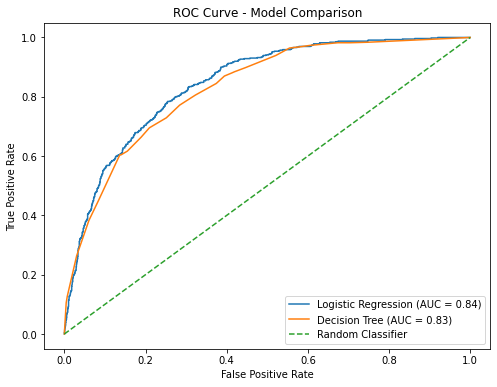

In [120]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predicted probabilities
y_prob_log = log_model.predict_proba(X_test_processed)[:, 1]
y_prob_dt = dt.predict_proba(X_test_processed)[:, 1]

# ROC curves
fpr_log, tpr_log, _ = roc_curve(y_test_encoded, y_prob_log)
fpr_dt, tpr_dt, _ = roc_curve(y_test_encoded, y_prob_dt)

# AUC
auc_log = roc_auc_score(y_test_encoded, y_prob_log)
auc_dt = roc_auc_score(y_test_encoded, y_prob_dt)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f'Logistic Regression (AUC = {auc_log:.2f})'
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f'Decision Tree (AUC = {auc_dt:.2f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Model Comparison')
plt.legend()
plt.show()

## Curious how the code works, why we use this algorithm, and what the images mean. I made a [companion](https://medium.com/@parulrajput27/01c51ddaccfc?source=friends_link&sk=4085e3287c367a8d0da645f82560fa7b) for you. 

# Happy Coding!!